# 1. Tracking the ACC with its kinetic energy (Sect. 2.2, Fig. 1, Fig. S5)

Companion notebook of **Martí-Solana et al., "Observational constraints on eddy saturation in the Antarctic Circumpolar Current"** (State of the Planet, Ocean State Report 11).

This notebook shows how the *energetic pathway* is identified with the half-power method and how sensitive the circumpolar position trend is to the parameters of the method.

It runs from the processed outputs in `outputs/` only (no raw data, no download), in about one minute. Every figure is drawn by its script in `figures/`; the cells before each figure load the tables behind it and print the values quoted in the paper. The scripts that produced each table from the raw data are named in the text and listed in the README.

In [1]:
from pathlib import Path
import io, os, subprocess, sys, tempfile
import numpy as np, pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src" / "osr11").is_dir() else ROOT.parent      # works from the repository root or from notebooks/
OUT = ROOT / "outputs"                                                 # processed outputs distributed with the repository
FIGDIR = Path(tempfile.mkdtemp(prefix="osr11_nb_"))                    # figures are re-rendered here, not into rendered/
pd.set_option("display.float_format", lambda v: f"{v:.3g}")


def render(script, width=1700):
    """Run one script of figures/ on outputs/ and show the figure it writes (PNG, 600 dpi, reduced here for display)."""
    args = [str(OUT), str(FIGDIR)] if script.startswith("figS") else [str(FIGDIR)]
    r = subprocess.run([sys.executable, str(ROOT / "figures" / script), *args], capture_output=True, text=True,
                       env=dict(os.environ, MPLBACKEND="Agg"))
    assert r.returncode == 0, r.stderr[-3000:]
    png = max((FIGDIR / "png").glob("*.png"), key=lambda p: p.stat().st_mtime)
    from PIL import Image as PILImage
    im = PILImage.open(png).convert("RGB"); im.thumbnail((width, 3 * width)); buf = io.BytesIO(); im.save(buf, "JPEG", quality=88)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(png.name, "written to", FIGDIR / "png")


def ci(row, s="slope", lo="lo", hi="hi", p="p", unit=""):
    pv = "p ≤ 0.003" if row[p] < 0.0034 else f"p = {row[p]:.2g}"          # 300 surrogates: the smallest attainable p is 1/301
    return f"{row[s]:+.1f} [{row[lo]:+.1f}, {row[hi]:+.1f}] {unit}, {pv}"


## The half-power method

At each longitude, peaks of the monthly kinetic energy (KE) above a threshold define an *envelope* that extends to 25 % of the peak; the **half-power latitude** divides the KE integrated over the envelope into two equal parts (Chambers, 2018). The threshold used in the paper is **20 % of the maximum of that longitude's 2001–2025 mean KE profile** inside the ACC band, so that it follows the strength of the local jets. Envelopes of the mean KE field define *tracks*; a track is retained when a monthly envelope is matched to it in at least 90 % of the 300 months.

The tracks are computed from the monthly fields by `scripts/02_circumpolar/02n_pathway_tracks.py` (shared code: `src/osr11/fronts.py`, `halfpower.py`).

In [2]:
Z = np.load(OUT / "x6" / "x6_relthr_tracks.npz")
acc, keep, lon = Z["acc"], Z["keep"], Z["lon"]
thr = 0.20 * Z["clim_max"] * 1e4                      # threshold at each of the 2880 longitudes, cm2 s-2
nlon = Z["clim_max"].size
print(f"climatological envelopes: {lon.size}; in the ACC band: {int(acc.sum())}; retained (matched in >= 90 % of months): {int(keep.sum())}")
print(f"longitudes with a retained track: {100 * np.unique(Z['j'][keep]).size / nlon:.0f} %")
print(f"threshold: {np.nanmin(thr):.0f} to {np.nanmax(thr):.0f} cm2 s-2 (median {np.nanmedian(thr):.0f})")

B = np.load(OUT / "a2" / "tracks_baseline.npz")       # fixed threshold of 200 cm2 s-2 (Chambers, 2018): the sensitivity set
kb = B["keep"] & B["acc"]
print(f"fixed 200 cm2 s-2 threshold: {int(kb.sum())} retained tracks on {100 * np.unique(B['j'][kb]).size / nlon:.0f} % of longitudes")

climatological envelopes: 4955; in the ACC band: 2511; retained (matched in >= 90 % of months): 1826
longitudes with a retained track: 63 %
threshold: 35 to 732 cm2 s-2 (median 117)
fixed 200 cm2 s-2 threshold: 900 retained tracks on 31 % of longitudes


## Figure 1

(a) KE of January 2001 with the half-power points detected in the ACC band; (b) the KE profile at 147.9° E with its envelope and half-power latitude; (c) the threshold at each longitude.

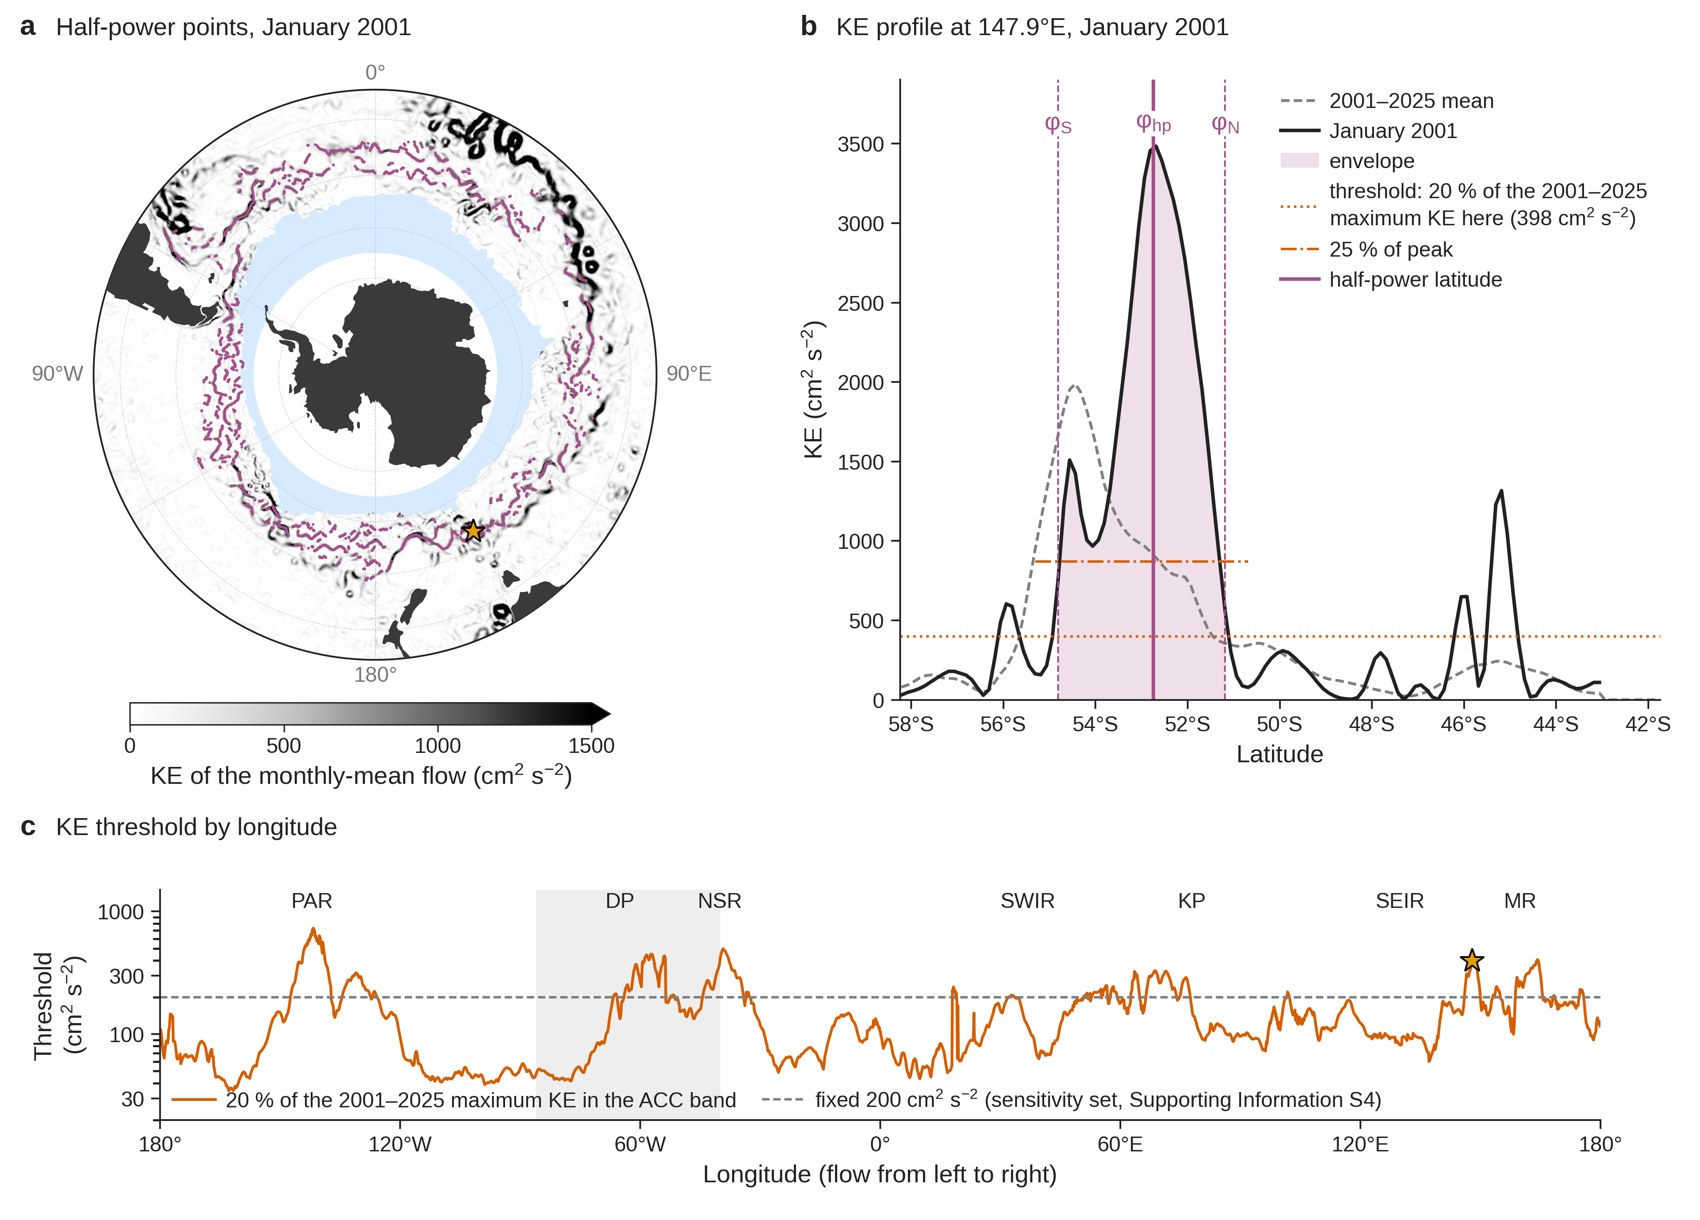

Figure1.png written to /tmp/osr11_nb_faac90xq/png


In [3]:
render("fig1_halfpower_method.py")

## Sensitivity of the position trend (Fig. S5)

The circumpolar trend of the half-power latitude for the threshold adopted in the paper, for the fixed 200 cm² s⁻² threshold and for variants of the fixed-threshold set. Trends are Theil–Sen slopes with intervals and p-values from autoregressive surrogates (`src/osr11/rstats.py`); the smallest attainable p is 1/301 ≈ 0.003.

In [4]:
X7 = pd.read_csv(OUT / "x7" / "x7_trends.csv")
r = X7[(X7.region == "circumpolar") & (X7.series == "lat_hp")].iloc[0]
print("longitude-dependent threshold (paper):", ci(r, unit="km per decade"), f"({r.n_tracks} tracks)")
RT = pd.read_csv(OUT / "retest" / "retest_summary.csv").set_index("key")
KM = 111.195                                             # km per degree of latitude; slopes in the table are degrees per year
rows = RT[RT.index.str.endswith("|ACC|lat_hp") & ~RT.index.str.startswith("relthr")]
tab = pd.DataFrame({"trend (km per decade)": 10 * KM * rows.slope, "lo": 10 * KM * rows.ci_lo, "hi": 10 * KM * rows.ci_hi, "p": rows.p_new})
tab.index = tab.index.str.replace("|ACC|lat_hp", "", regex=False)
tab.round(2)

longitude-dependent threshold (paper): +2.6 [-5.9, +11.1] km per decade, p = 0.46 (1826 tracks)


,trend (km per decade),lo,hi,p
key,,,,
baseline,-0.54,-4.17,3.09,0.74
frac20,0.02,-4.15,4.19,0.99
frac33,-0.94,-4.62,2.75,0.56
frac50,-1,-4.81,2.8,0.53
minw200,1.85,-5.89,9.58,0.58
minw300,-1.9,-8.24,4.44,0.5
minw50,-1.53,-3.81,0.74,0.16
thr150,0.05,-4.99,5.1,0.98
thr250,-0.69,-4.24,2.86,0.65


`baseline` is the fixed 200 cm² s⁻² threshold; the other rows change one parameter at a time (threshold, envelope fraction to which the envelope extends, minimum width). No trend is significant.

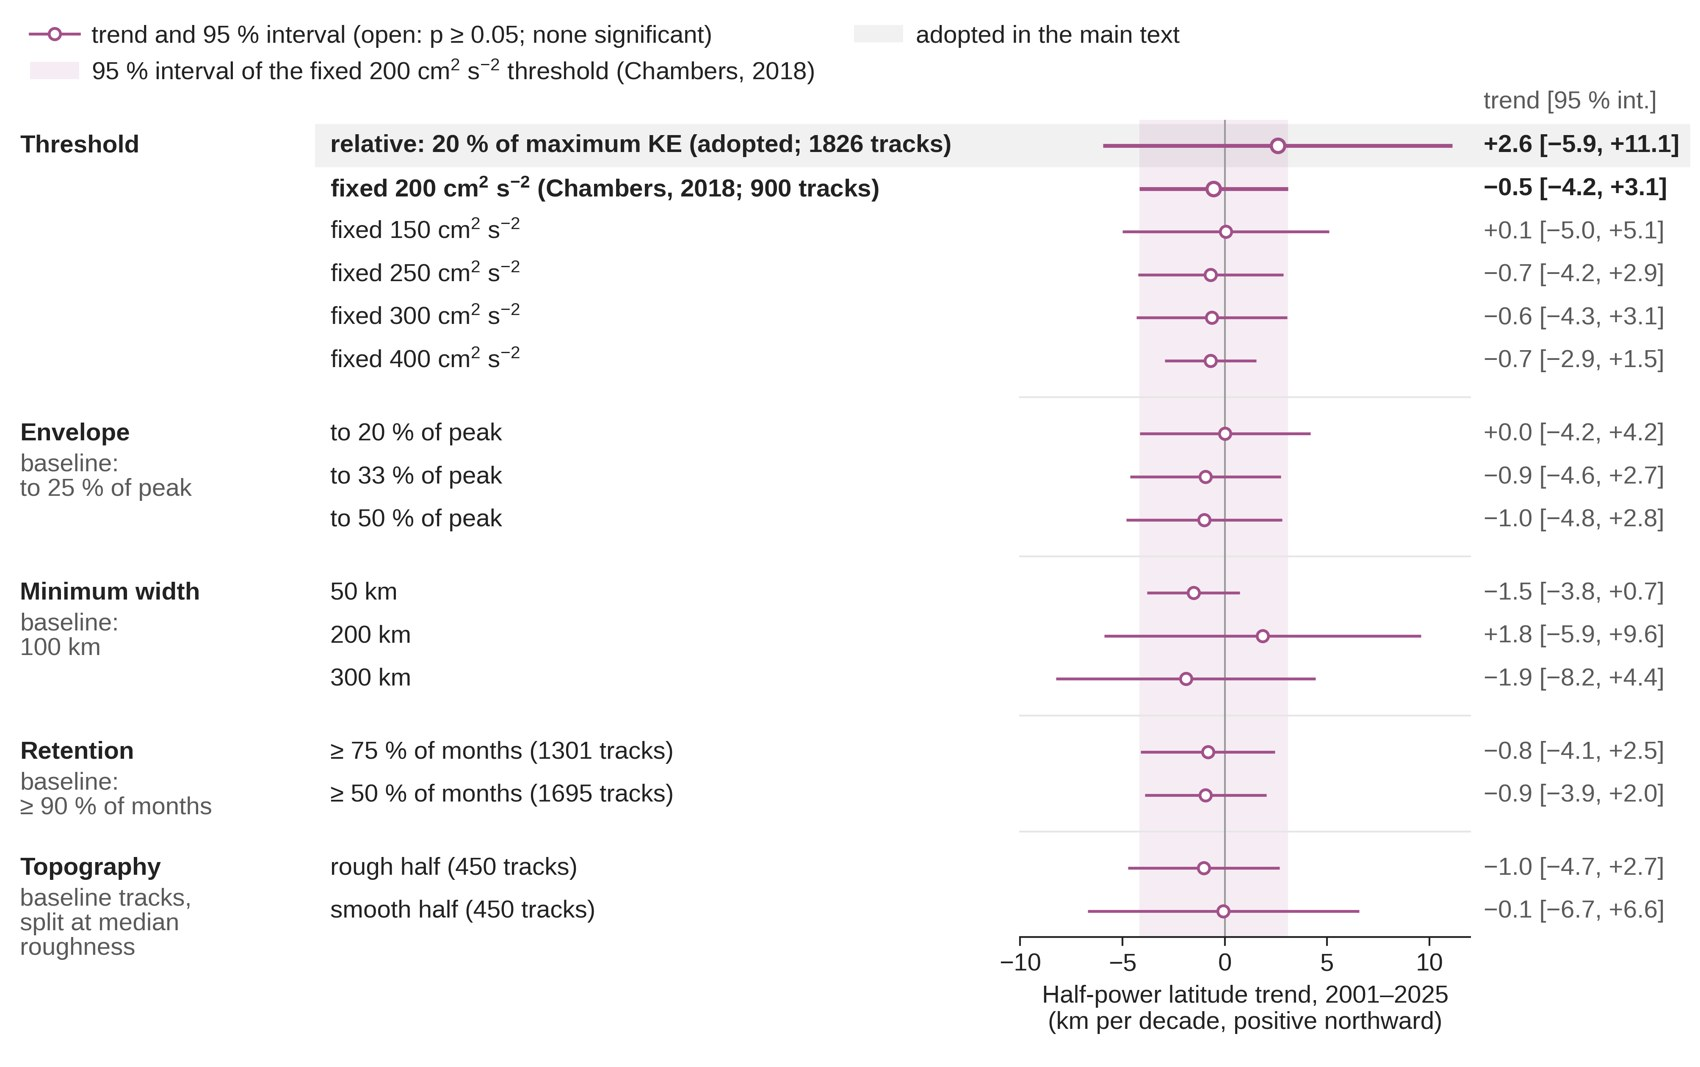

FigureS5.png written to /tmp/osr11_nb_faac90xq/png


In [5]:
render("figS5_pathway_robustness.py")